#  Titanic Survival Predictions

ce notebook intrioduit mon projet de prediction des **survivants** de titanic avec le **DeepLearning** et precisement le **MLP**, en bref on va faire de l'analyse et se faire des idées sur dans ce  notebook

## 1.Importations des librairies

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import numpy as np

## 2.Load Dataset

In [8]:
file_path = Path('data/titanic.csv')

try:
    if not file_path.exists():
        raise FileNotFoundError
    df = pd.read_csv(file_path)
    print('Données chargées')
except FileNotFoundError:
    print(f"le fichier {file_path.name} n'existe pas dans {file_path.parent}")

Données chargées


## 3.Analyse simple et basique

In [9]:
# head

df.head()

,Unnamed: 0,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [10]:
# descriptions stats
df.describe()

,Unnamed: 0,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,445.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,222.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,445.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,667.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,890.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [15]:
# columns infos
df.info('\n')
print(f"collones qualitatives : {list(df.select_dtypes(include='object'))}")
print(f"Quantitatives : {list(df.select_dtypes(include=[np.number]))}")

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   891 non-null    int64  
 1   survived     891 non-null    int64  
 2   pclass       891 non-null    int64  
 3   sex          891 non-null    str    
 4   age          714 non-null    float64
 5   sibsp        891 non-null    int64  
 6   parch        891 non-null    int64  
 7   fare         891 non-null    float64
 8   embarked     889 non-null    str    
 9   class        891 non-null    str    
 10  who          891 non-null    str    
 11  adult_male   891 non-null    bool   
 12  deck         203 non-null    str    
 13  embark_town  889 non-null    str    
 14  alive        891 non-null    str    
 15  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(5), str(7)
memory usage: 123.9 KB
collones qualitatives : ['sex', 'embarked', 'class', 'who', 'deck', 'embark_town'

C:\Users\G\AppData\Local\Temp\ipykernel_11476\1107836978.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(f"collones qualitatives : {list(df.select_dtypes(include='object'))}")


In [ ]:
# description et recherche des anomalies

print(f"Metrics Globales : ")
print(f"{df.shape[0]} lignes")
print(f"{df.shape[1]} colonnes")
print(f"{df.isnull().sum().sum()} valeures manquates")
print(f"{df.duplicated().sum()} doublons detectées")
print(f"{df.shape[0]*df.shape[1]} valeures ")


Metrics Globales : 
891 lignes
16 colonnes
869 valeures manquates
0 doublons detectées
14256 valeures totales


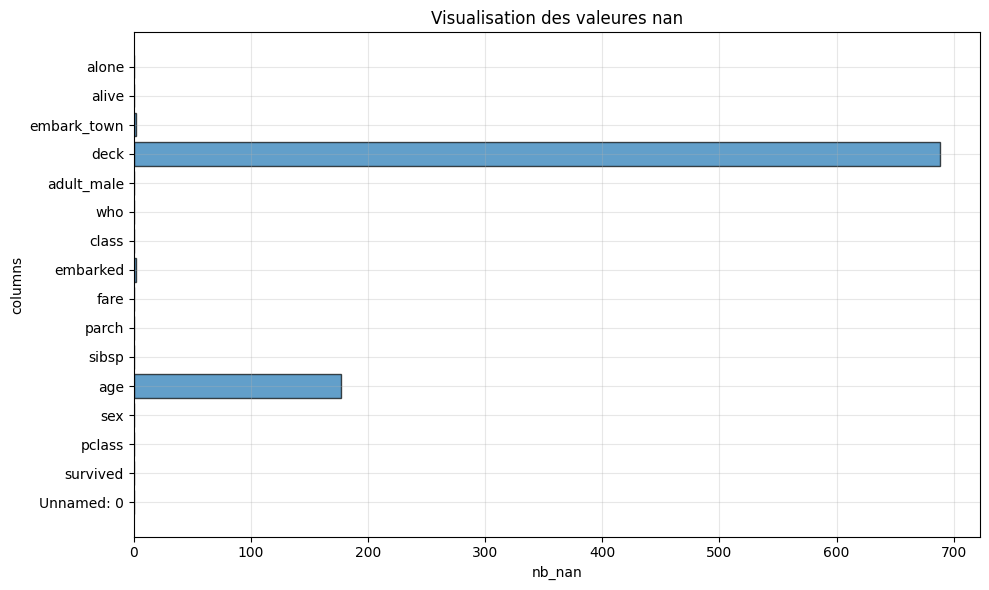

In [40]:
# valeures manquates par colonnes
nan_values = {f"{col} : {nan_value} "for col,nan_value in zip(df.columns,df.isnull().sum())}

plt.figure(figsize=(10,6))
plt.barh(list(df.columns),df.isnull().sum(),alpha=0.7,edgecolor='black')
plt.grid(True,alpha=0.3)
plt.title('Visualisation des valeures nan')
plt.ylabel('columns')
plt.xlabel('nb_nan')
plt.tight_layout()
plt.show()
    

In [42]:
# distreibution de la variable de survie
print(df.survived.value_counts)


<bound method IndexOpsMixin.value_counts of 0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: survived, Length: 891, dtype: int64>


In [36]:
print(nan_values)

{'embark_town : 2 ', 'sibsp : 0 ', 'alone : 0 ', 'survived : 0 ', 'adult_male : 0 ', 'deck : 688 ', 'Unnamed: 0 : 0 ', 'embarked : 2 ', 'alive : 0 ', 'parch : 0 ', 'who : 0 ', 'age : 177 ', 'fare : 0 ', 'class : 0 ', 'pclass : 0 ', 'sex : 0 '}


<Figure size 1200x400 with 0 Axes>

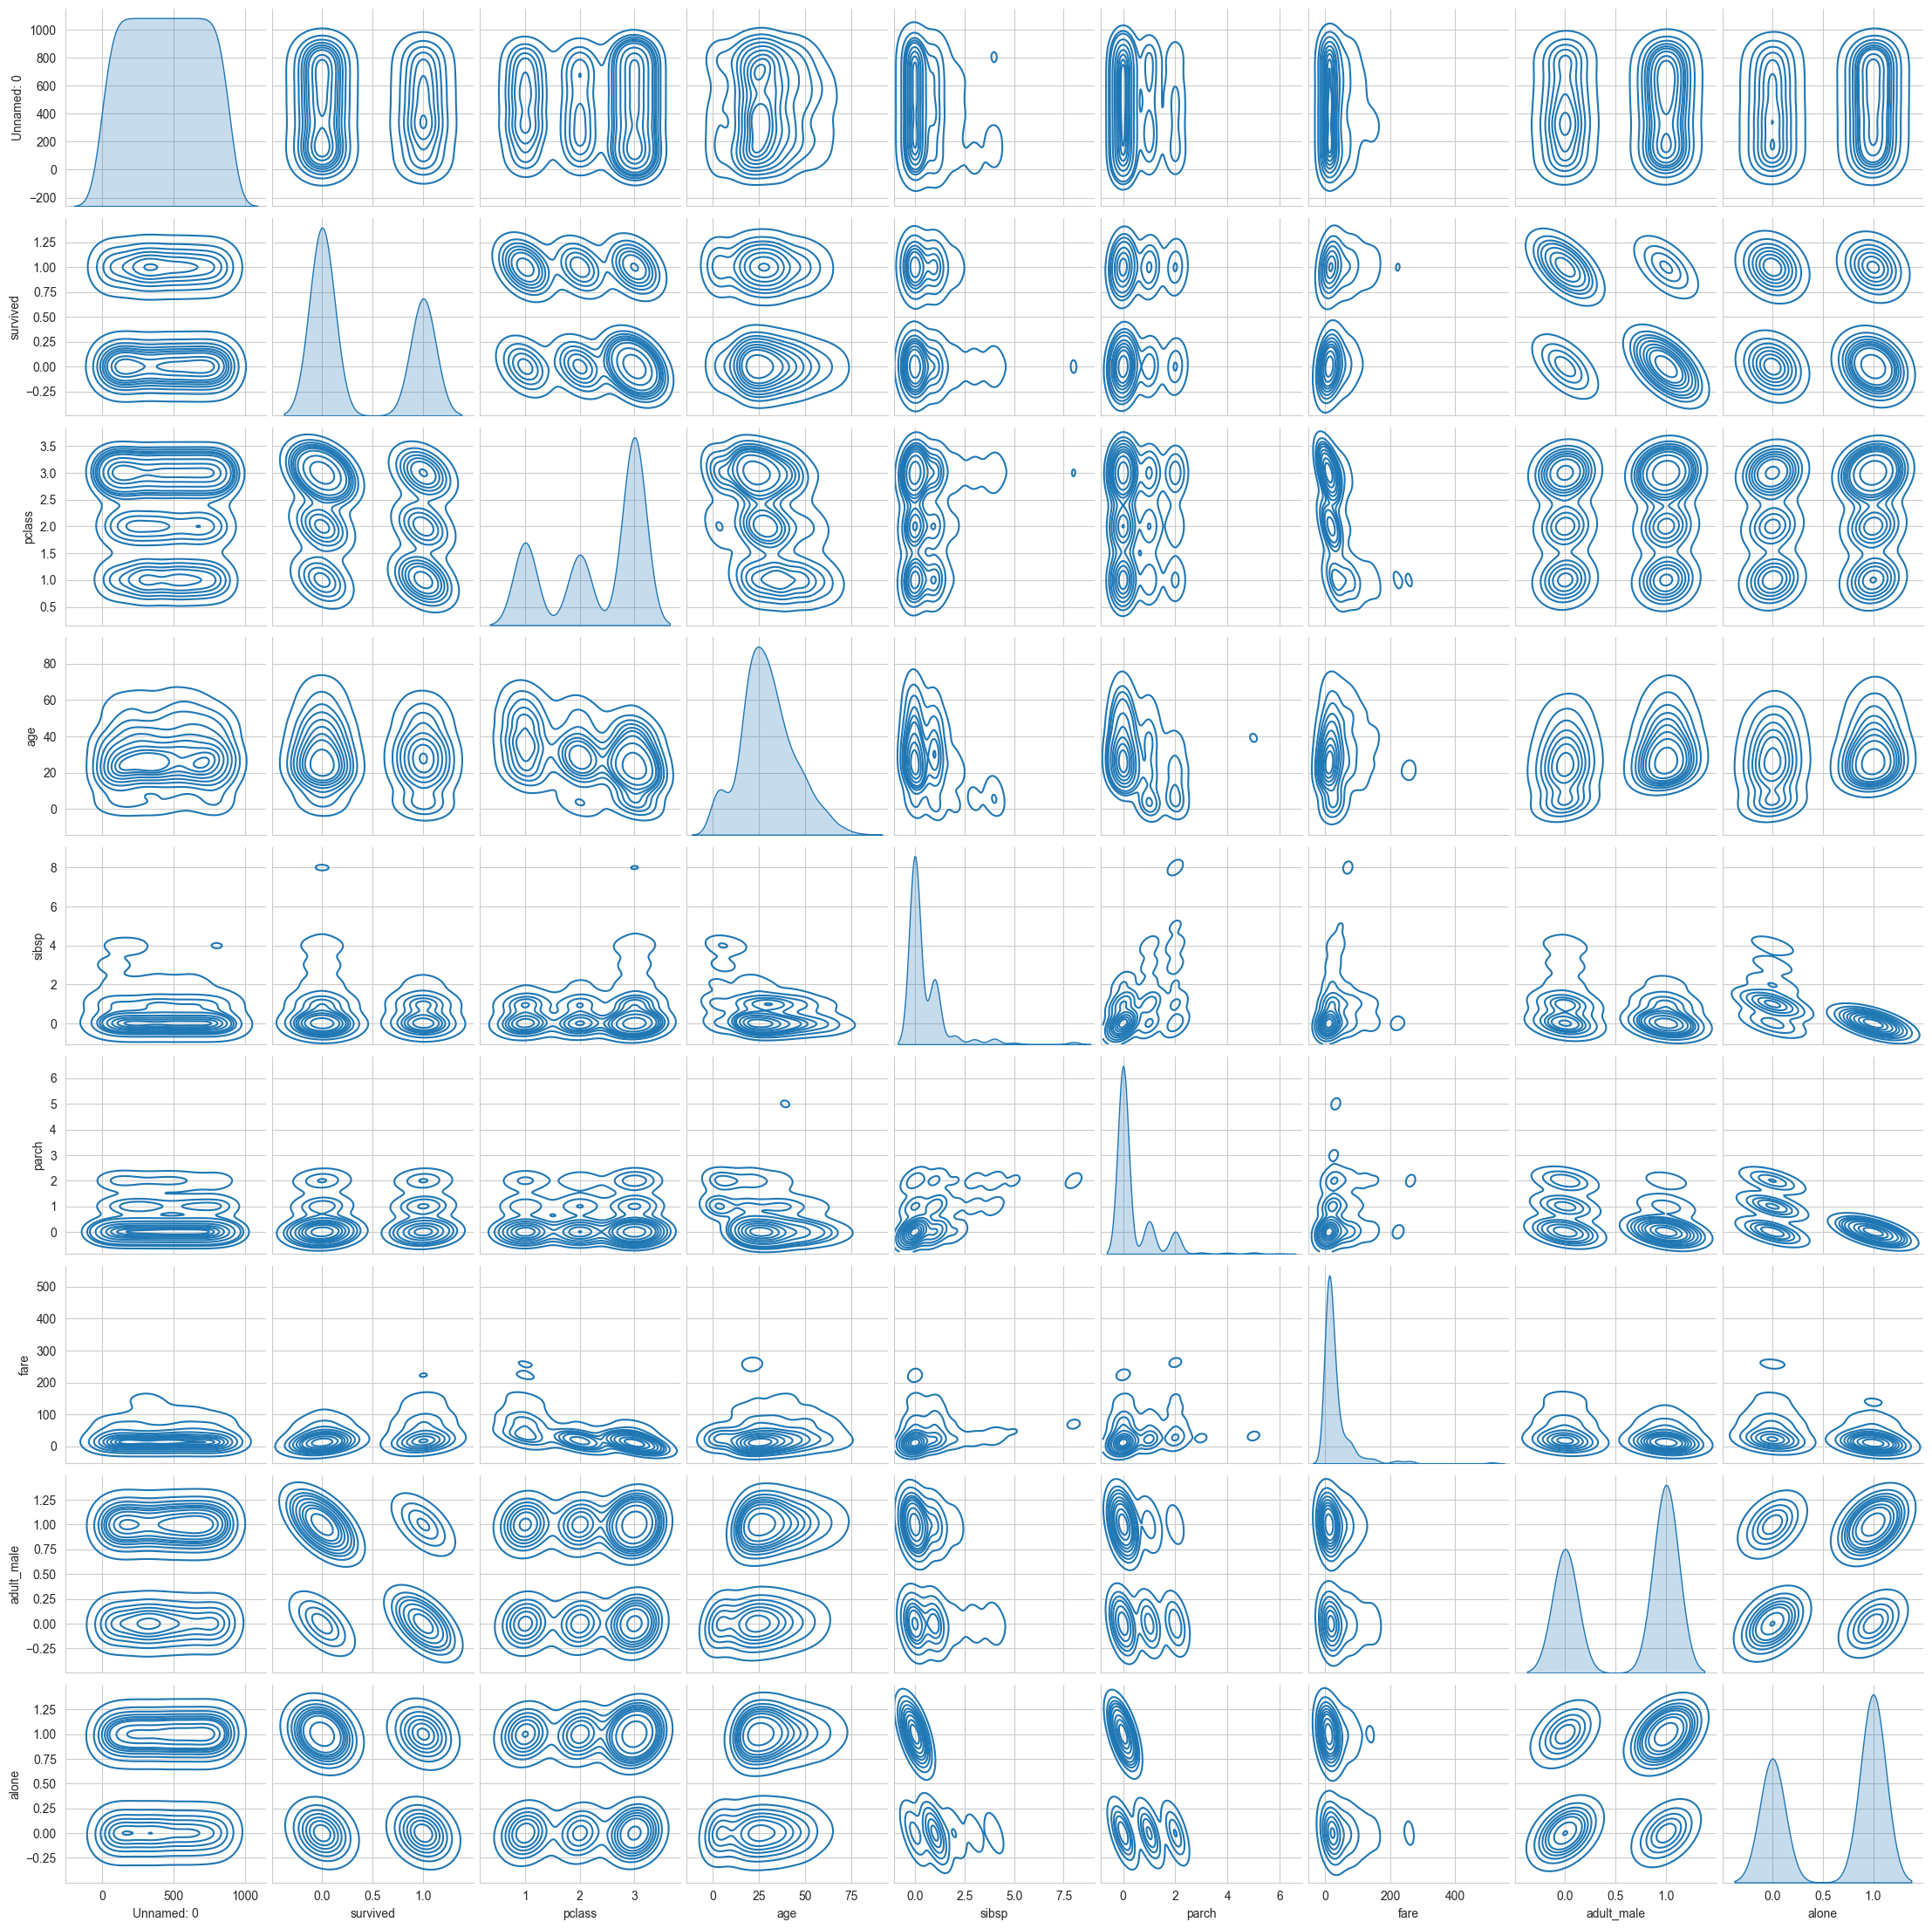

In [41]:
# pairplot pour voir toute les distribution

sns.set_style('whitegrid')
plt.figure(figsize=(12,4))
sns.pairplot(df,kind='kde')
plt.show()